**CS 4140 – Deep Learning · L07 · CNNs II: a complete classification workflow** &nbsp; [![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Bolufe-Rohler/4140-deep-learning/blob/main/lectures/L07_cnns-2/L07_cnn_cifar10.ipynb)

Run the first code cell before anything else. In Colab, *File → Save a copy in Drive* keeps your own changes.

In [ ]:
# ▶ Run this cell first. It gets the course code and this lecture's saved results and data,
#   in Google Colab or on your own computer.
LECTURE = "L07_cnns-2"
REPO = "https://github.com/Bolufe-Rohler/4140-deep-learning"
import os, sys, subprocess
root = os.path.abspath(os.path.join("..", ".."))
if not os.path.isfile(os.path.join(root, "cs4140_setup.py")):  # not inside the course repo (e.g. Colab)
    root = "/content/cs4140" if "google.colab" in sys.modules else os.path.abspath("cs4140")
    if not os.path.isdir(root):
        subprocess.run(["git", "clone", "--quiet", "--depth", "1", REPO, root], check=True)
    os.chdir(os.path.join(root, "lectures", LECTURE))
sys.path.insert(0, root)
import cs4140_setup
cs4140_setup.fetch_assets(LECTURE)

# CNN II demo: our images, end to end

CS 4140 Deep Learning · Lecture 7

The LeNet-style network from the "CNN Example" slides, trained on CIFAR-10 with the complete workflow:
three data splits, minibatches, a training loop, validation after every epoch, the best checkpoint,
and one final look at the test set. We compare it with the dense network from 15 January.

**In class** keep `TRAIN = False`: the notebook loads the saved runs in `runs/` and only evaluates,
which takes well under a minute on a laptop. Set `TRAIN = True` to retrain both networks
(about 20 epochs each: a few minutes per network on a laptop CPU, seconds per epoch on a GPU).
CIFAR-10 (163 MB) downloads into `data/` the first time.

In [1]:
import json, random, time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
import torchvision.transforms as T
from torch.utils.data import DataLoader, random_split
from matplotlib.ticker import PercentFormatter

TRAIN = False                       # True: retrain both networks; False: load the saved runs
EPOCHS, BATCH, LR, SEED = 20, 64, 1e-3, 4140
DATA_DIR, RUN_DIR = Path('data'), Path('runs')
RUN_DIR.mkdir(exist_ok=True)
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
CLASSES = ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']
torch.manual_seed(SEED); random.seed(SEED); np.random.seed(SEED)
plt.rcParams.update({'font.size': 14})       # readable on a projector
print('PyTorch', torch.__version__, '| device:', DEVICE)

PyTorch 2.14.1+cpu | device: cpu


## 1. Data: three splits, three jobs

* **training** (45,000 images): the weights are fitted to these;
* **validation** (5,000): after every epoch we check accuracy here and keep the best checkpoint;
* **test** (10,000): looked at once, at the very end, to report how well the chosen model generalises.

The training images arrive in **minibatches** of 64, reshuffled every epoch.

In [2]:
MEAN, STD = (0.4914, 0.4822, 0.4465), (0.2470, 0.2435, 0.2616)   # per-channel statistics of CIFAR-10
tf = T.Compose([T.ToTensor(), T.Normalize(MEAN, STD)])

full_train = torchvision.datasets.CIFAR10(DATA_DIR, train=True, download=True, transform=tf)
test_set = torchvision.datasets.CIFAR10(DATA_DIR, train=False, download=True, transform=tf)
train_set, val_set = random_split(full_train, [45_000, 5_000], generator=torch.Generator().manual_seed(SEED))

train_loader = DataLoader(train_set, batch_size=BATCH, shuffle=True)
val_loader = DataLoader(val_set, batch_size=512)
test_loader = DataLoader(test_set, batch_size=512)

xb, yb = next(iter(train_loader))
print('training / validation / test:', len(train_set), len(val_set), len(test_set))
print('one minibatch of images:', tuple(xb.shape), ' -> (batch, channels, height, width)')
print('and its labels:', tuple(yb.shape), [CLASSES[i] for i in yb[:5]], '...')

training / validation / test: 45000 5000 10000
one minibatch of images: (64, 3, 32, 32)  -> (batch, channels, height, width)
and its labels: (64,) ['horse', 'airplane', 'frog', 'dog', 'frog'] ...


## 2. The network from the "CNN Example" slides, and the dense network from 15 January

PyTorch writes shapes channels first, (channels, height, width): the slide's (28, 28, 8) is (8, 28, 28) here.
The parameter counts match the slide's table row by row (ReLU rows left out). There is no softmax layer:
`nn.CrossEntropyLoss` applies it inside the loss.

In [3]:
def lenet_style():
    return nn.Sequential(
        nn.Conv2d(3, 8, kernel_size=5), nn.ReLU(), nn.MaxPool2d(2),     # CONV1 + POOL1
        nn.Conv2d(8, 16, kernel_size=5), nn.ReLU(), nn.MaxPool2d(2),    # CONV2 + POOL2
        nn.Flatten(),                                                   # 5 x 5 x 16 = 400 numbers
        nn.Linear(400, 120), nn.ReLU(),                                 # FC3
        nn.Linear(120, 84), nn.ReLU(),                                  # FC4
        nn.Linear(84, 10))                                              # 10 scores; softmax lives in the loss


def dense_15jan():
    return nn.Sequential(
        nn.Flatten(),                                                   # 32 x 32 x 3 = 3,072 numbers
        nn.Linear(3072, 512), nn.ReLU(),
        nn.Linear(512, 256), nn.ReLU(),
        nn.Linear(256, 10))


def shape_table(model):
    x = torch.zeros(1, 3, 32, 32)
    print(f"{'layer':<10}{'output shape':>16}{'parameters':>13}")
    for layer in model:
        x = layer(x)
        n = sum(p.numel() for p in layer.parameters())
        if not isinstance(layer, nn.ReLU):
            print(f"{type(layer).__name__:<10}{str(tuple(x.shape[1:])):>16}{n:>13,}")
    print(f"{'total':<10}{'':>16}{sum(p.numel() for p in model.parameters()):>13,}")


shape_table(lenet_style())
print()
shape_table(dense_15jan())

layer         output shape   parameters
Conv2d         (8, 28, 28)          608
MaxPool2d      (8, 14, 14)            0
Conv2d        (16, 10, 10)        3,216
MaxPool2d       (16, 5, 5)            0
Flatten             (400,)            0
Linear              (120,)       48,120
Linear               (84,)       10,164
Linear               (10,)          850
total                            62,958

layer         output shape   parameters
Flatten            (3072,)            0
Linear              (512,)    1,573,376
Linear              (256,)      131,328
Linear               (10,)        2,570
total                         1,707,274


## 3. The training loop

Every minibatch goes through the same four steps: **forward** (the model's scores), **loss** (softmax + cross-entropy),
**backward** (the gradient of the loss with respect to every weight) and **step** (the optimizer nudges the weights).
After each epoch we measure accuracy on the validation set and save the model whenever it is the best so far.
Wednesday's lecture opens up `loss.backward()` and the optimizer.

In [4]:
loss_fn = nn.CrossEntropyLoss()        # softmax + cross-entropy, averaged over the minibatch


def evaluate(model, loader):
    model.eval()
    correct = total = 0
    loss_sum = 0.0
    with torch.no_grad():
        for x, y in loader:
            x, y = x.to(DEVICE), y.to(DEVICE)
            scores = model(x)
            loss_sum += loss_fn(scores, y).item() * len(y)
            correct += (scores.argmax(1) == y).sum().item()
            total += len(y)
    return loss_sum / total, correct / total


def train(make_model, name, epochs=EPOCHS):
    torch.manual_seed(SEED)
    model = make_model().to(DEVICE)
    optimizer = torch.optim.Adam(model.parameters(), lr=LR)
    history, best = [], 0.0
    for epoch in range(1, epochs + 1):
        model.train()
        start, seen, correct, loss_sum = time.time(), 0, 0, 0.0
        for x, y in train_loader:                    # one minibatch at a time
            x, y = x.to(DEVICE), y.to(DEVICE)
            scores = model(x)                        # forward
            loss = loss_fn(scores, y)                # loss
            optimizer.zero_grad()
            loss.backward()                          # backward
            optimizer.step()                         # step
            seen += len(y)
            loss_sum += loss.item() * len(y)
            correct += (scores.argmax(1) == y).sum().item()
        val_loss, val_acc = evaluate(model, val_loader)          # validate after every epoch
        history.append(dict(epoch=epoch, train_loss=loss_sum / seen, train_acc=correct / seen,
                            val_loss=val_loss, val_acc=val_acc))
        saved = ''
        if val_acc > best:                                       # keep the best checkpoint
            best = val_acc
            torch.save(model.state_dict(), RUN_DIR / f'{name}_best.pt')
            saved = '  <- best so far, saved'
        print(f'{name:>5} epoch {epoch:2d}: training accuracy {correct / seen:.3f}, '
              f'validation accuracy {val_acc:.3f} ({time.time() - start:.0f} s){saved}')
    with open(RUN_DIR / f'{name}_history.json', 'w') as f:
        json.dump(history, f, indent=1)
    return history

In [5]:
saved = all((RUN_DIR / f'{n}_history.json').exists() and (RUN_DIR / f'{n}_best.pt').exists()
            for n in ('dense', 'cnn'))
if TRAIN or not saved:
    history = {'dense': train(dense_15jan, 'dense'), 'cnn': train(lenet_style, 'cnn')}
else:
    history = {n: json.load(open(RUN_DIR / f'{n}_history.json')) for n in ('dense', 'cnn')}
    print(f'Loaded the saved runs in {RUN_DIR}/. This is what training printed:')
    for name, h in history.items():
        best = 0.0
        for r in h:
            mark = '  <- best so far, saved' if r['val_acc'] > best else ''
            best = max(best, r['val_acc'])
            print(f"{name:>5} epoch {r['epoch']:2d}: training accuracy {r['train_acc']:.3f}, "
                  f"validation accuracy {r['val_acc']:.3f}{mark}")

Loaded the saved runs in runs/. This is what training printed:
dense epoch  1: training accuracy 0.404, validation accuracy 0.436  <- best so far, saved
dense epoch  2: training accuracy 0.477, validation accuracy 0.481  <- best so far, saved
dense epoch  3: training accuracy 0.516, validation accuracy 0.500  <- best so far, saved
dense epoch  4: training accuracy 0.541, validation accuracy 0.516  <- best so far, saved
dense epoch  5: training accuracy 0.570, validation accuracy 0.530  <- best so far, saved
dense epoch  6: training accuracy 0.592, validation accuracy 0.512
dense epoch  7: training accuracy 0.617, validation accuracy 0.516
dense epoch  8: training accuracy 0.640, validation accuracy 0.522
dense epoch  9: training accuracy 0.658, validation accuracy 0.533  <- best so far, saved
dense epoch 10: training accuracy 0.678, validation accuracy 0.537  <- best so far, saved
dense epoch 11: training accuracy 0.698, validation accuracy 0.524
dense epoch 12: training accuracy 0.715

## 4. Learning curves: which checkpoint do we keep?

Dashed lines are training accuracy, solid lines validation accuracy; the dot marks the epoch we keep.
Training accuracy is averaged over each epoch while the weights are still changing, which is why it starts
below validation accuracy.
Both networks keep improving on the training images while their validation accuracy levels off, and the CNN
levels off much higher. The gap that opens between the two curves is overfitting: Friday's topic.

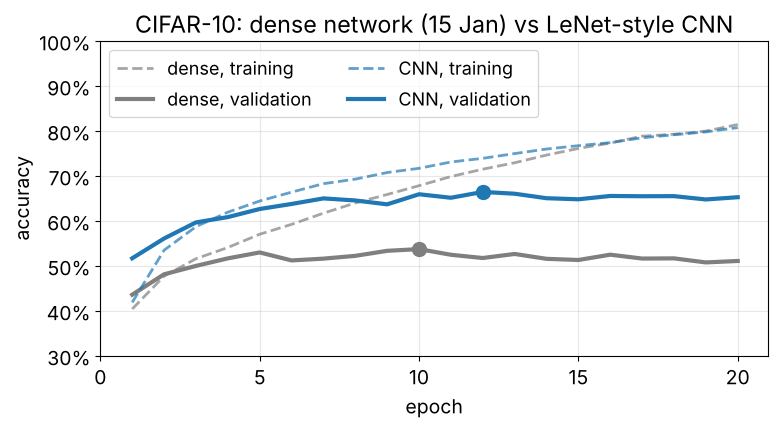

In [6]:
fig, ax = plt.subplots(figsize=(8, 4.5))
for name, label, colour in [('dense', 'dense', 'tab:gray'), ('cnn', 'CNN', 'tab:blue')]:
    h = history[name]
    epochs = [r['epoch'] for r in h]
    ax.plot(epochs, [r['train_acc'] for r in h], '--', color=colour, lw=2, alpha=0.7, label=f'{label}, training')
    ax.plot(epochs, [r['val_acc'] for r in h], '-', color=colour, lw=3, label=f'{label}, validation')
    best = max(h, key=lambda r: r['val_acc'])
    ax.plot(best['epoch'], best['val_acc'], 'o', color=colour, ms=10, zorder=3)
ax.set_xlabel('epoch')
ax.set_ylabel('accuracy')
ax.set_ylim(0.3, 1.0)
ax.yaxis.set_major_formatter(PercentFormatter(1.0))
ax.set_xticks(range(0, EPOCHS + 1, 5))
ax.grid(alpha=0.3)
ax.legend(loc='upper left', ncol=2, fontsize=13)
ax.set_title('CIFAR-10: dense network (15 Jan) vs LeNet-style CNN')
plt.tight_layout()
plt.savefig(RUN_DIR / 'curves.png', dpi=200)
plt.show()

## 5. Touch the test set once

We load each network's best checkpoint and evaluate it on the 10,000 test images, once.

In [7]:
results = {}
for name, make in [('dense', dense_15jan), ('cnn', lenet_style)]:
    model = make().to(DEVICE)
    model.load_state_dict(torch.load(RUN_DIR / f'{name}_best.pt', map_location=DEVICE))
    _, test_acc = evaluate(model, test_loader)
    best = max(history[name], key=lambda r: r['val_acc'])
    results[name] = dict(parameters=sum(p.numel() for p in model.parameters()), best_epoch=best['epoch'],
                         val_acc=best['val_acc'], test_acc=test_acc)
    print(f"{name:>5}: {results[name]['parameters']:>9,} parameters | best epoch {best['epoch']:2d} | "
          f"validation {best['val_acc']:.1%} | test {test_acc:.1%}")
with open(RUN_DIR / 'test_results.json', 'w') as f:
    json.dump(results, f, indent=1)
cnn = model                         # the CNN was loaded last

dense: 1,707,274 parameters | best epoch 10 | validation 53.7% | test 52.6%


  cnn:    62,958 parameters | best epoch 12 | validation 66.4% | test 66.0%


## 6. Predictions on images the network never saw

Sixteen test images, each titled with the CNN's top guess and its softmax probability.
Green is right; red is wrong, with the true class underneath. Which mistakes are understandable?

11 of 16 right


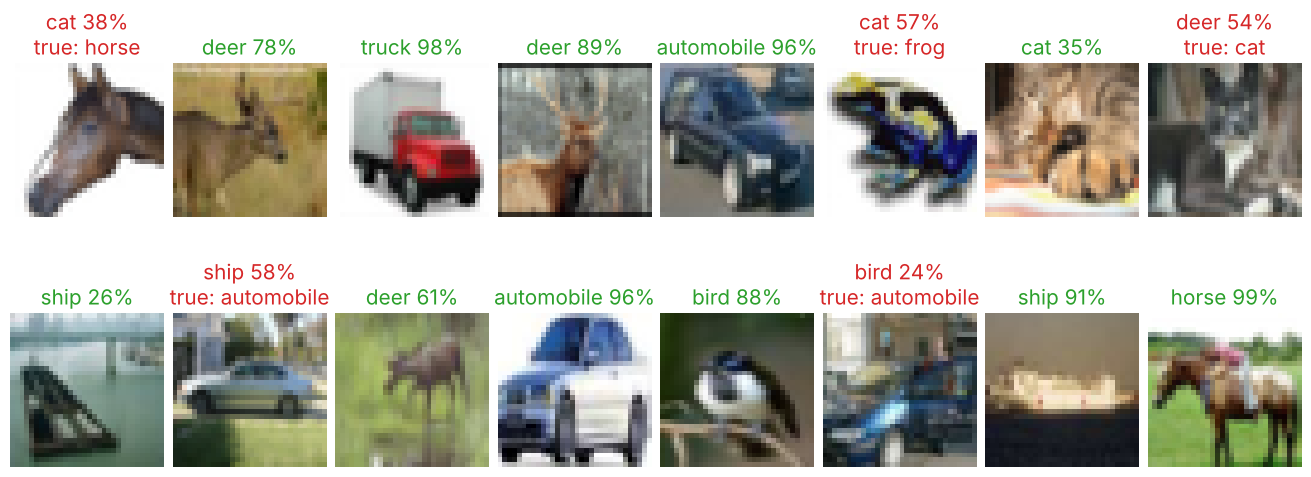

In [8]:
raw_test = torchvision.datasets.CIFAR10(DATA_DIR, train=False, download=False)   # untransformed, for display
picks = torch.randperm(len(test_set), generator=torch.Generator().manual_seed(7))[:16].tolist()
cnn.eval()
with torch.no_grad():
    probs = F.softmax(cnn(torch.stack([test_set[i][0] for i in picks]).to(DEVICE)), dim=1).cpu()   # for display

fig, axes = plt.subplots(2, 8, figsize=(13, 5), layout='constrained')
for ax, i, p in zip(axes.flat, picks, probs):
    image, label = raw_test[i]
    guess = int(p.argmax())
    right = guess == label
    ax.imshow(image)
    ax.axis('off')
    title = f'{CLASSES[guess]} {p[guess]:.0%}' + ('' if right else f'\ntrue: {CLASSES[label]}')
    ax.set_title(title, fontsize=15, color='tab:green' if right else 'tab:red')
shown = [dict(index=i, true=CLASSES[raw_test[i][1]], guess=CLASSES[int(p.argmax())], prob=round(float(p.max()), 4))
         for i, p in zip(picks, probs)]
print(f"{sum(r['true'] == r['guess'] for r in shown)} of 16 right")
with open(RUN_DIR / 'predictions.json', 'w') as f:
    json.dump(shown, f, indent=1)
plt.savefig(RUN_DIR / 'predictions.png', dpi=200)
plt.show()

## What to take away

* The CNN uses about 27 times fewer parameters than the dense network and generalises better: filters shared
  across the image, instead of one weight per pixel per unit.
* The workflow is the same for every supervised model this term: split the data, train in minibatches,
  choose the checkpoint on validation, report the test set once.
* Both networks fit the training images better and better while validation levels off; the gap is about twice
  as wide for the dense network. That gap is overfitting: Friday's topic.